# 1. IoT data analysis: what the smart meters recorded

This notebook analyses the data that **Node-RED** stored in **MongoDB** (database `gridguard_iot`).

```
5 simulated smart meters --MQTT--> Node-RED --> MongoDB  (readings, alerts, diagnosis)
                                        \--> ThingSpeak (cloud charts)
```

One real second in Node-RED is one minute of meter time, so a full day of data takes 24 minutes to collect. The notebook always uses the **latest session** (the most recent time Node-RED was started).

During the recorded day these events were switched on from the dashboard:

| Meter | Event |
|---|---|
| MTR-01 | meter wired backwards (reversed) |
| MTR-02 | stuck meter for a few hours |
| MTR-00 | spiking meter for a couple of hours |
| MTR-03 | EV charger (charges in the evening) |
| MTR-04 | solar panels (export during daylight) |

In [1]:
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from pymongo import MongoClient

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
COLORS = {"MTR-00": "#2a78d6", "MTR-01": "#eb6834", "MTR-02": "#1baf7a", "MTR-03": "#eda100", "MTR-04": "#e87ba4"}

db = MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=3000).gridguard_iot
session = db.readings.find_one(sort=[("received_at", -1)])["session"]
readings = pd.DataFrame(db.readings.find({"session": session}, {"_id": 0}))
readings["time"] = pd.to_datetime(readings["ts"])
day_end = readings["time"].min().normalize() + pd.Timedelta(days=1)
readings = readings[readings["time"] < day_end].copy()
readings["hour"] = readings["time"].dt.hour
diagnosis = pd.DataFrame(db.diagnosis.find({"session": session}, {"_id": 0}))
diagnosis = diagnosis[pd.to_datetime(diagnosis["hour_start"]) < day_end].copy()
print(f"Session started {session}")
print(f"{len(readings)} readings from {readings.meter_id.nunique()} meters, meter time {readings.time.min():%d %b %H:%M} to {readings.time.max():%d %b %H:%M}")
print(f"{len(diagnosis)} hourly diagnoses, {readings['flags'].str.len().gt(0).sum()} readings flagged by Node-RED")
readings[["meter_id", "ts", "power_w", "voltage_v", "flags"]].head()

Session started 2026-11-22T20:13:48.295Z
7135 readings from 5 meters, meter time 22 Nov 00:13 to 22 Nov 23:59
120 hourly diagnoses, 454 readings flagged by Node-RED


,meter_id,ts,power_w,voltage_v,flags
0,MTR-02,2026-11-22T00:13:00.000Z,100.0,228.2,[]
1,MTR-01,2026-11-22T00:13:00.000Z,170.4,230.1,[]
2,MTR-03,2026-11-22T00:13:00.000Z,125.9,230.7,[]
3,MTR-04,2026-11-22T00:13:00.000Z,148.8,228.6,[]
4,MTR-00,2026-11-22T00:13:00.000Z,133.8,231.8,[]


## 1. A full day of readings

Each panel is one home. Red dots are readings that Node-RED's *Check reading* function flagged in real time. Things to notice:

- **MTR-01** stays below zero: the meter was installed backwards.
- **MTR-02** draws a perfectly flat line for a while: the meter froze.
- **MTR-00** shows a few impossible jumps of 5 to 15 kW: spikes.
- **MTR-03** has a big 7 kW block in the evening: an EV charging.
- **MTR-04** dips below zero around midday only: solar panels exporting.

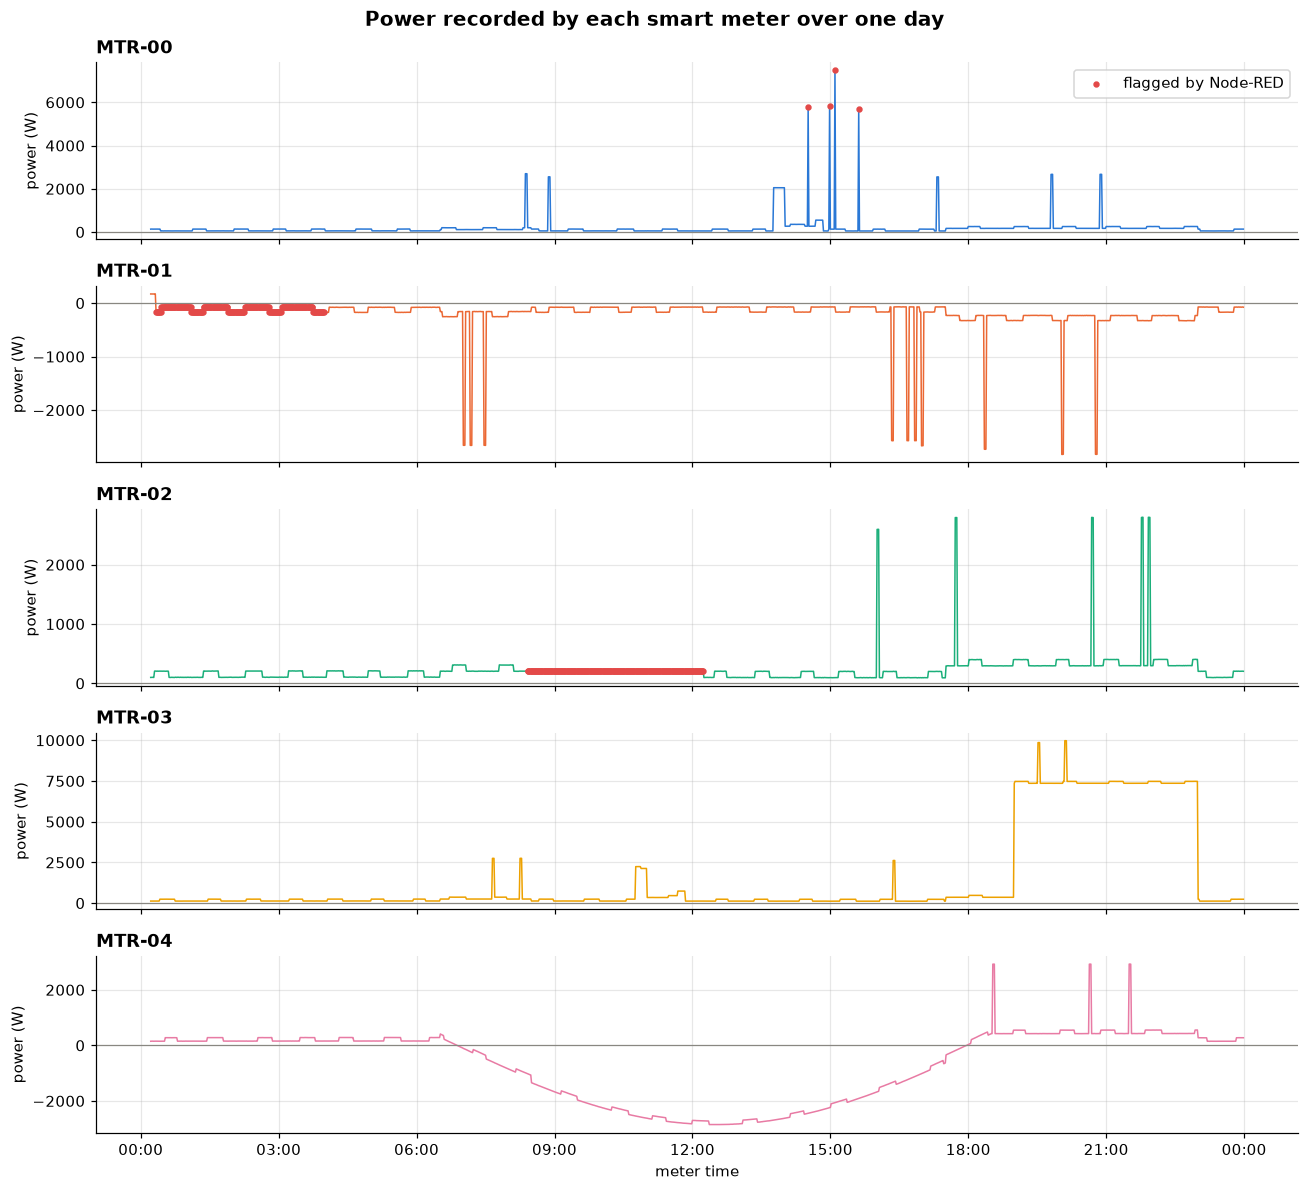

In [2]:
fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
for ax, (meter, data) in zip(axes, readings.groupby("meter_id")):
    ax.plot(data["time"], data["power_w"], color=COLORS[meter], lw=1)
    flagged = data[data["flags"].str.len() > 0]
    ax.scatter(flagged["time"], flagged["power_w"], color="#e34948", s=10, zorder=3, label="flagged by Node-RED")
    ax.axhline(0, color="#898781", lw=0.8)
    ax.set_ylabel("power (W)")
    ax.set_title(meter, loc="left", fontweight="bold")
axes[0].legend(loc="upper right")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[-1].set_xlabel("meter time")
fig.suptitle("Power recorded by each smart meter over one day", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## 2. Daily load profile

Average power per hour of the day. Blue means the home draws power and red means it exports (negative). Normal homes are pale at night and darker in the evening. The reversed meter is red all day, and the solar home turns red only in daylight hours.

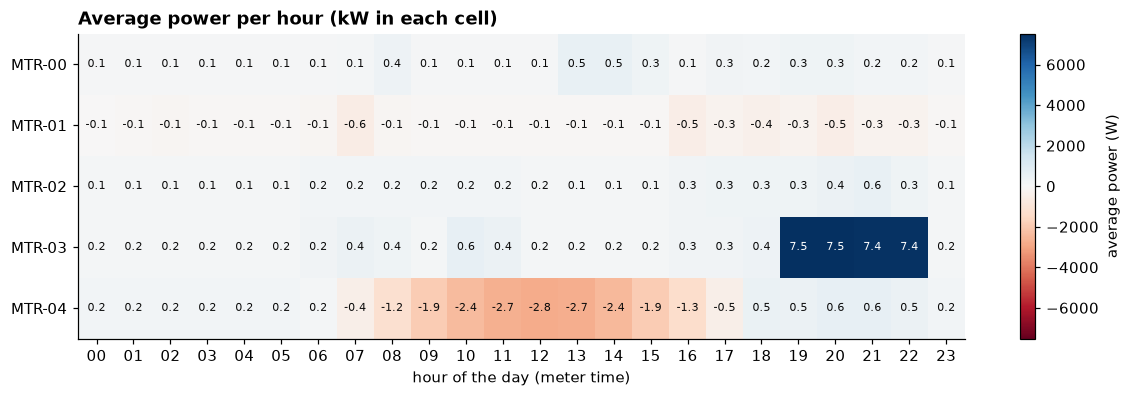

In [3]:
profile = readings.pivot_table(index="meter_id", columns="hour", values="power_w", aggfunc="mean")
limit = np.nanmax(np.abs(profile.values))
fig, ax = plt.subplots(figsize=(13, 3.6))
image = ax.imshow(profile.values, cmap="RdBu", norm=TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit), aspect="auto")
ax.set_xticks(range(len(profile.columns)), [f"{h:02d}" for h in profile.columns])
ax.set_yticks(range(len(profile.index)), profile.index)
ax.set_xlabel("hour of the day (meter time)")
ax.grid(False)
for (row, col), value in np.ndenumerate(profile.values):
    if not np.isnan(value):
        ax.text(col, row, f"{value / 1000:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(value) > limit * 0.5 else "#0b0b0b")
fig.colorbar(image, ax=ax, label="average power (W)")
ax.set_title("Average power per hour (kW in each cell)", loc="left", fontweight="bold")
plt.show()

## 3. Energy used by each home

Energy (kWh) is average power times time. The EV home uses by far the most. The solar home's net use is lower because it exported part of the day. The reversed meter even reports *negative* energy, which is impossible for a normal house and a strong sign of a wiring fault.

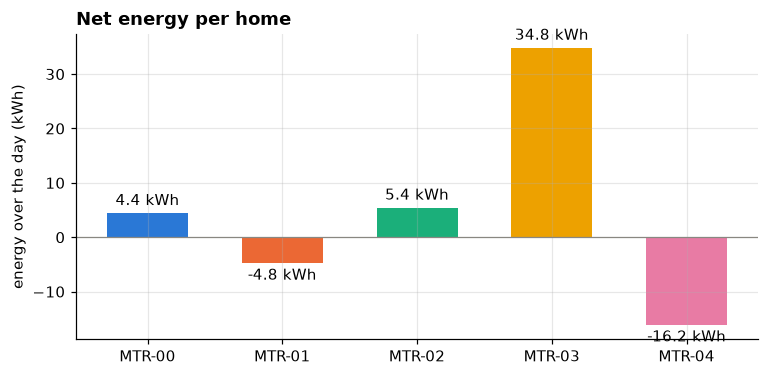

In [4]:
energy = readings.groupby("meter_id")["power_w"].sum() / 60 / 1000
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(energy.index, energy.values, color=[COLORS[m] for m in energy.index], width=0.6)
ax.bar_label(bars, fmt="%.1f kWh", padding=3)
ax.axhline(0, color="#898781", lw=0.8)
ax.set_ylabel("energy over the day (kWh)")
ax.set_title("Net energy per home", loc="left", fontweight="bold")
plt.show()

## 4. Problems flagged in real time by Node-RED

Node-RED checks every reading as it arrives:

| Flag | Rule |
|---|---|
| `stuck` | 10 identical readings in a row |
| `spike` | a reading more than 4 kW above both of its neighbours (Node-RED waits one second to see the next reading) |
| `reverse` | negative power between midnight and 4 am, when solar cannot be exporting |
| `implausible` | more than 23 kW (more than a home supply can deliver) |

The chart counts how many readings got each flag.

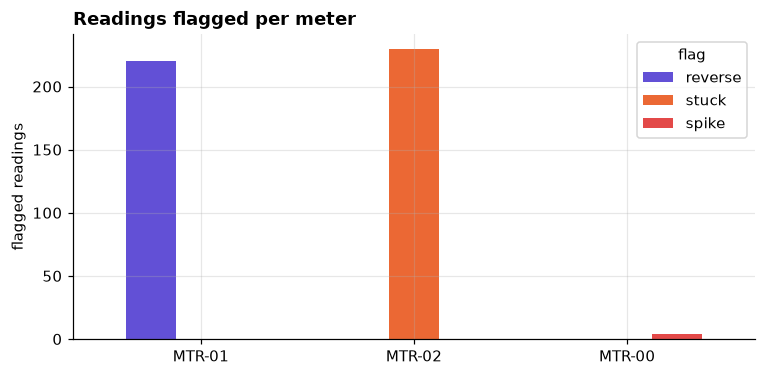

flags,reverse,stuck,spike
meter_id,,,
MTR-01,220,0,0
MTR-02,0,230,0
MTR-00,0,0,4


In [5]:
flags = readings[["meter_id", "flags"]].explode("flags").dropna()
counts = flags.value_counts().unstack(fill_value=0) if len(flags) else pd.DataFrame()
fig, ax = plt.subplots(figsize=(8, 3.6))
if counts.empty:
    ax.text(0.5, 0.5, "no flagged readings in this session", ha="center", transform=ax.transAxes)
else:
    flag_colors = {"stuck": "#eb6834", "spike": "#e34948", "reverse": "#6250d6", "implausible": "#898781"}
    counts.plot.bar(ax=ax, color=[flag_colors.get(c, "#898781") for c in counts.columns], rot=0, width=0.7)
    ax.legend(title="flag")
ax.set_xlabel("")
ax.set_ylabel("flagged readings")
ax.set_title("Readings flagged per meter", loc="left", fontweight="bold")
plt.show()
counts

## 5. Edge analytics: hourly diagnosis

Every 60 readings (one meter hour), Node-RED's *Hourly diagnosis* function summarises the hour and decides what is going on. This is the GridGuard idea running at the edge:

- **meter fault**: frozen readings, impossible spikes, or negative power while the sun is down. The meter is broken and the data must not be trusted. A meter caught negative in the dark stays a fault in daylight too.
- **genuine change**: export only in daylight (solar), or more than 30 minutes above 5 kW (EV). The home really changed and the data is valid.
- **normal**: nothing unusual.

The difference matters. A broken meter should be repaired, but a home with a new EV should simply be accepted.

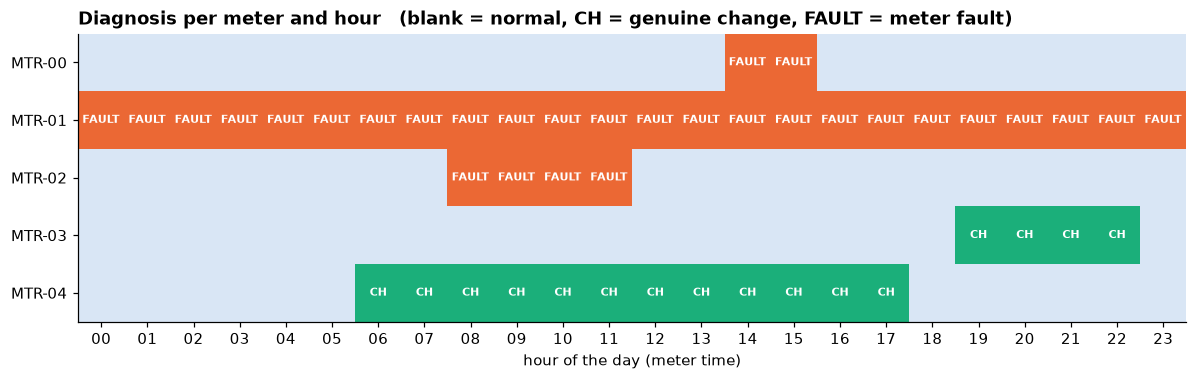

diagnosis,genuine change,meter fault,normal
meter_id,,,
MTR-00,0,2,22
MTR-01,0,24,0
MTR-02,0,4,20
MTR-03,4,0,20
MTR-04,12,0,12


In [6]:
labels = {"normal": 0, "genuine change": 1, "meter fault": 2}
diagnosis["hour"] = pd.to_datetime(diagnosis["hour_start"]).dt.hour
grid = diagnosis.pivot_table(index="meter_id", columns="hour", values="diagnosis", aggfunc="last")
codes = grid.replace(labels).astype(float)
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.imshow(codes.values, cmap=ListedColormap(["#d9e6f5", "#1baf7a", "#eb6834"]), vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(grid.columns)), [f"{h:02d}" for h in grid.columns])
ax.set_yticks(range(len(grid.index)), grid.index)
ax.grid(False)
short = {"normal": "", "genuine change": "CH", "meter fault": "FAULT"}
for (row, col), value in np.ndenumerate(grid.values):
    if isinstance(value, str):
        ax.text(col, row, short[value], ha="center", va="center", fontsize=7, fontweight="bold", color="white")
ax.set_xlabel("hour of the day (meter time)")
ax.set_title("Diagnosis per meter and hour   (blank = normal, CH = genuine change, FAULT = meter fault)", loc="left", fontweight="bold")
plt.show()
diagnosis.groupby(["meter_id", "diagnosis"]).size().unstack(fill_value=0)

In [7]:
diagnosis[diagnosis["diagnosis"] != "normal"][["meter_id", "hour_start", "avg_w", "diagnosis", "reason"]].head(15)

,meter_id,hour_start,avg_w,diagnosis,reason
1,MTR-01,2026-11-22T00:13:00.000Z,-69,meter fault,negative power with no sun (wired backwards)
6,MTR-01,2026-11-22T01:13:00.000Z,-121,meter fault,negative power with no sun (wired backwards)
11,MTR-01,2026-11-22T02:13:00.000Z,-108,meter fault,negative power with no sun (wired backwards)
16,MTR-01,2026-11-22T03:13:00.000Z,-111,meter fault,negative power with no sun (wired backwards)
21,MTR-01,2026-11-22T04:13:00.000Z,-107,meter fault,negative power with no sun (wired backwards)
26,MTR-01,2026-11-22T05:13:00.000Z,-112,meter fault,negative power with no sun (wired backwards)
31,MTR-01,2026-11-22T06:13:00.000Z,-416,meter fault,negative day and night (wired backwards)
34,MTR-04,2026-11-22T06:13:00.000Z,98,genuine change,exporting in daylight (solar panels?)
36,MTR-01,2026-11-22T07:13:00.000Z,-317,meter fault,negative day and night (wired backwards)
39,MTR-04,2026-11-22T07:13:00.000Z,-592,genuine change,exporting in daylight (solar panels?)


## 6. Reading the same data back from ThingSpeak

Every 20 seconds Node-RED also uploads a summary to a **ThingSpeak** channel:

| Field | Meaning |
|---|---|
| field1 to field5 | average power of MTR-00 to MTR-04 (W) |
| field6 | total neighbourhood load (W) |
| field7 | readings flagged in the last 20 s |
| field8 | number of meters with a problem |

To run this part, set your channel ID (and read key, if the channel is private) before starting Jupyter:

```powershell
$env:THINGSPEAK_CHANNEL_ID = "1234567"
$env:THINGSPEAK_READ_KEY = "XXXXXXXXXXXXXXXX"
```

In [8]:
channel = os.getenv("THINGSPEAK_CHANNEL_ID")
if not channel:
    print("THINGSPEAK_CHANNEL_ID is not set, so the ThingSpeak part is skipped. Open your channel on thingspeak.com to see the same charts.")
else:
    params = {"results": 500}
    if os.getenv("THINGSPEAK_READ_KEY"):
        params["api_key"] = os.getenv("THINGSPEAK_READ_KEY")
    feed = requests.get(f"https://api.thingspeak.com/channels/{channel}/feeds.json", params=params, timeout=10).json()
    cloud = pd.DataFrame(feed["feeds"])
    cloud["time"] = pd.to_datetime(cloud["created_at"])
    for column in [f"field{i}" for i in range(1, 9)]:
        cloud[column] = pd.to_numeric(cloud[column], errors="coerce")
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
    top.plot(cloud["time"], cloud["field6"], color="#2a78d6")
    top.set_ylabel("total load (W)")
    top.set_title(f"ThingSpeak channel {channel}: {feed['channel']['name']}", loc="left", fontweight="bold")
    bottom.bar(cloud["time"], cloud["field7"], width=0.0002, color="#e34948")
    bottom.set_ylabel("flagged readings")
    bottom.set_xlabel("upload time")
    fig.tight_layout()
    plt.show()

THINGSPEAK_CHANNEL_ID is not set, so the ThingSpeak part is skipped. Open your channel on thingspeak.com to see the same charts.


## Summary

- **Node-RED** collected, checked and stored every reading, and diagnosed each meter every hour, without any Python running.
- **MongoDB** kept the raw readings, the alerts and the diagnoses, ready for analysis like this.
- **ThingSpeak** gives the same data as cloud charts that can be opened from anywhere.
- The edge diagnosis told broken meters (reversed, stuck, spiking) apart from real changes (EV, solar), which is the core idea of GridGuard. Notebook 2 shows why this matters when homes train a shared AI model.